# 1.1 — RQ0b: Is there a structural break in how US population growth responds to income?

For each decade d: Δln(pop)_{i,d} = α_d + β_d · ln(income per capita)_{i,d}.
States 1880–2020 (Klein, Easterlin, BEA); metros 1940–2020 (IPUMS 1940 wages, Census medians, BEA).
Break tests pool all decades with decade fixed effects (see Claude/methods/analysis-methods.md).
Findings are descriptive and associational.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from us_housing_crisis_analysis.config import PROCESSED_DATA_DIR, RQ0B_METRO_START, RQ0B_STATE_START, TABLES_DIR
from us_housing_crisis_analysis.modeling import breaks
from us_housing_crisis_analysis.plots import MUTED, SERIES_MARKERS, TEXT, apply_style, save_figure

apply_style()
metro_panel = pd.read_parquet(PROCESSED_DATA_DIR / "us_metro_longrun.parquet")
panels = {
    "states": breaks.prepare_decade_panel(pd.read_parquet(PROCESSED_DATA_DIR / "us_state_longrun.parquet"), RQ0B_STATE_START),
    "metros": breaks.prepare_decade_panel(metro_panel, RQ0B_METRO_START),
}
# Robustness: 1940 metro income with missing wages left out of the denominator (not counted as 0)
metros_wages_reported = breaks.prepare_decade_panel(
    metro_panel.assign(income_pc=metro_panel.income_pc_wages_reported), RQ0B_METRO_START)
{k: (v.decade.min(), v.decade.max(), v.geo_id.nunique(), len(v)) for k, v in panels.items()}

2026-10-14 18:41:38.259 | INFO     | us_housing_crisis_analysis.config:<module>:11 - PROJ_ROOT path is: /Users/lrubin/Documents/code/US Housing Crisis Analysis


{'states': (np.int64(1880), np.int64(2010), 51, 691),
 'metros': (np.int64(1940), np.int64(2010), 386, 3078)}

## β_d by decade

decade    beta      se    n
version                                
states  0     1880  0.1828  0.1096   45
        1     1890  0.0913  0.0465   47
        2     1900  0.1406  0.0552   48
        3     1910  0.0832  0.0404   48
        4     1920  0.0852  0.0472   48
        5     1930  0.0308  0.0295   49
        6     1940  0.1328  0.0322   49
        7     1950  0.2756  0.0850   51
        8     1960  0.2252  0.0727   51
        9     1970 -0.0581  0.1188   51
        10    1980  0.2106  0.1015   51
        11    1990 -0.0794  0.0759   51
        12    2000 -0.0434  0.0449   51
        13    2010 -0.0092  0.0492   51
metros  0     1940  0.0827  0.0311  382
        1     1950  0.0401  0.0444  382
        2     1960  0.0465  0.0358  384
        3     1970 -0.1325  0.0555  386
        4     1980  0.0444  0.0481  386
        5     1990 -0.0723  0.0393  386
        6     2000 -0.0725  0.0284  386
        7     2010  0.0513  0.0214  386

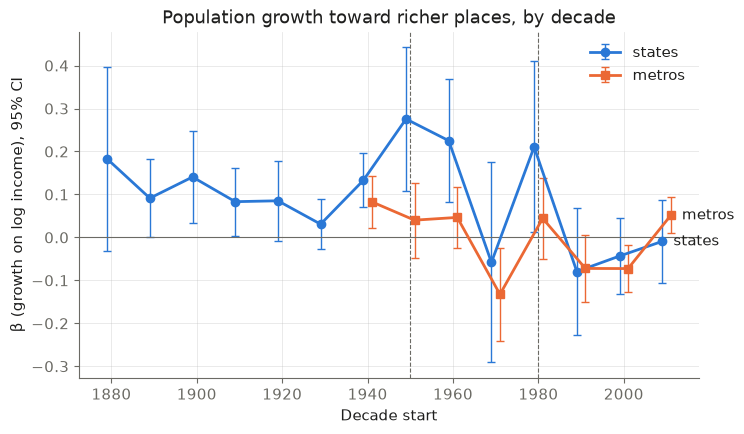

In [2]:
betas = {k: breaks.decade_betas(v) for k, v in panels.items()}
fig, ax = plt.subplots()
for (name, b), offset, marker in zip(betas.items(), (-1, 1), SERIES_MARKERS):
    line = ax.errorbar(b.decade + offset, b.beta, yerr=1.96 * b.se, marker=marker, capsize=3,
                       elinewidth=1, label=name)
    last = b.iloc[-1]
    ax.annotate(name, (last.decade + offset, last.beta), xytext=(8, 0), textcoords="offset points",
                va="center", color=TEXT)
ax.axhline(0, color=MUTED, lw=0.8)
for d in (1950, 1980):
    ax.axvline(d, color=MUTED, ls="--", lw=0.8)
ax.set(xlabel="Decade start", ylabel="β (growth on log income), 95% CI",
       title="Population growth toward richer places, by decade")
ax.legend(loc="upper right")
save_figure(fig, "rq0b_betas")
pd.concat(betas, names=["version"]).round(4)

## Break tests: main specification and robustness

In [3]:
rows = []
for name, dp in panels.items():
    specs = {
        "main": dp,
        "standardized income": breaks.standardize_within_decade(dp),
        "drop source-change decades": dp[~dp.decade.isin(breaks.source_change_decades(dp))],
    }
    if name == "metros":
        specs["1940 missing wages excluded"] = metros_wages_reported
    for spec, d in specs.items():
        for year in (1950, 1980):
            if d.decade.min() < year <= d.decade.max():
                r = breaks.chow_test(d, year)
                rows.append({"version": name, "spec": spec, "test": f"chow_{year}",
                             "statistic": r.statistic, "p_value": r.p_value, "breaks": ""})
        s = breaks.break_search(d)
        rows.append({"version": name, "spec": spec, "test": "break_search_bic",
                     "statistic": s.bic[s.breaks], "p_value": float("nan"),
                     "breaks": " ".join(map(str, s.breaks))})
tests = pd.DataFrame(rows)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
tests.to_csv(TABLES_DIR / "rq0b_tests.csv", index=False)
tests.round(4)

,version,spec,test,statistic,p_value,breaks
0,states,main,chow_1950,0.0014,0.9697,
1,states,main,chow_1980,2.8164,0.0933,
2,states,main,break_search_bic,-2660.8739,NaN,
3,states,standardized income,chow_1950,2.1345,0.1440,
4,states,standardized income,chow_1980,13.5323,0.0002,
5,states,standardized income,break_search_bic,-2652.4224,NaN,1970
6,states,drop source-change decades,chow_1950,0.0247,0.8751,
7,states,drop source-change decades,chow_1980,3.4496,0.0633,
8,states,drop source-change decades,break_search_bic,-2235.1646,NaN,
9,metros,main,chow_1950,6.4943,0.0108,


## Sanity check against Ganong & Shoag (2017)

Ganong & Shoag find that population flowed toward high-income states from 1880 until about
1980, and that this weakened afterwards. The state-level β_d above should show the same
pattern (positive and fairly stable before 1980, lower after). If it does not, check the
pipeline before interpreting the results.

**Finding (run 2026-10-14, after the Plan 1 review fixes):** The sanity check passes. State β_d is positive in every decade from 1880 to 1960 (0.03–0.28) and is zero or negative from 1990 on (−0.08 to −0.01), the direction Ganong & Shoag report; the 1970s (negative) and 1980s (0.21) are noisy. Metro β_d is lower than the state value in 1950–1980 and close to it from 1990 on. The break tests do not pin down the timing: for states, neither Chow test rejects at 5% in the main specification (1950 p = 0.97, 1980 p = 0.09) and the BIC search picks no break, but with income standardized within decade the 1980 Chow test rejects (p < 0.001) and the search picks 1970. For metros, the 1950 Chow test rejects in every specification (p = 0.004–0.03), including with missing 1940 wages left out rather than counted as zero; but the period before 1950 is the 1940 decade alone, the only wage-only decade, so this test can't separate a change in behavior from the change of income concept. The search picks 1970, which is also when the income source switches to BEA; with the source-change decades dropped it picks 1990 and the 1980 Chow test rejects (p = 0.01). Limitations: 1940 metro income is wages only, 1950–60 metro income is a population-weighted mean of county medians, the metro panel starts in 1940, and with 14 (states) or 8 (metros) decades the break search has little power to separate 1970, 1980 and 1990.